# Car-Hacking (HCRL) — corrida FINAL (3 semillas, 30 épocas)

Notebook independiente: **no** carga OTIDS. Ya viene configurado: `QUICK = False`, 3 semillas, primeras 1,000,000 tramas por archivo y resultados en `CAN_IDS_FINAL_EVIDENCE/CARHACKING`.

1. Los 4 CSV deben estar en `MyDrive/Datasets/CarHacking`.
2. *Entorno de ejecución → Cambiar tipo → GPU T4* (si no hay, "Conectarse sin una GPU").
3. *Entorno de ejecución → Ejecutar todo*. Autoriza Drive cuando lo pida.
4. Tiempo: ~30–40 min con GPU, ~2 h en CPU. Al final, envía captura de CH3, del resumen y de la tabla de densidad.


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 1. Configuración

In [ ]:
# ============================================================
# R0. CONFIGURACIÓN
# ============================================================
import os, json, time, gc, warnings
import numpy as np
import pandas as pd
from scipy.stats import binomtest
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, PredefinedSplit, GridSearchCV
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix)
warnings.filterwarnings("ignore", category=FutureWarning)

QUICK = False                    # True = prueba rápida; False = experimento completo
SEEDS = [42] if QUICK else [42, 7, 123, 2024, 31415]
EPOCHS_MAX = 3 if QUICK else 30
BATCH_SIZE = 64
WINDOW_SIZE = 20

OUT_DIR = "/content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/CARHACKING"
os.makedirs(OUT_DIR, exist_ok=True)

FILE_ORDER = ["Attack_free_dataset.txt", "DoS_attack_dataset.txt",
              "Fuzzy_attack_dataset.txt", "Impersonation_attack_dataset.txt"]
LABEL_MAP = {f: i for i, f in enumerate(FILE_ORDER)}
CLASS_NAMES = ["Attack-free", "DoS", "Fuzzy", "Impersonation"]

import pickle
RES_CSV = os.path.join(OUT_DIR, "revision_results.csv")
PRED_PKL = os.path.join(OUT_DIR, "revision_predictions.pkl")
RESULTS = []          # una fila por (experimento, modelo, semilla)
PREDICTIONS = {}      # predicciones de prueba para McNemar

# ---- REANUDAR: si la sesión se cortó, se cargan los resultados ya guardados en Drive ----
RESUME = False   # Car-Hacking empieza limpio en su propia carpeta
if RESUME and os.path.isfile(RES_CSV):
    RESULTS = pd.read_csv(RES_CSV).to_dict("records")
    print(f"Reanudando: {len(RESULTS)} resultados previos cargados de {RES_CSV}")
if RESUME and os.path.isfile(PRED_PKL):
    with open(PRED_PKL, "rb") as fh:
        PREDICTIONS = pickle.load(fh)
    print(f"Reanudando: {len(PREDICTIONS)} vectores de predicción cargados")

def save_results(name="revision_results.csv"):
    pd.DataFrame(RESULTS).to_csv(os.path.join(OUT_DIR, name), index=False)
    with open(PRED_PKL, "wb") as fh:
        pickle.dump(PREDICTIONS, fh)

def _has_row(exp, model, seed):
    return any(r["experiment"] == exp and r["model"] == model and int(r["seed"]) == int(seed) for r in RESULTS)

def need(exp, model, seed):
    # True = hay que entrenar. Se salta si ya hay resultado; la semilla 42 además necesita
    # sus predicciones guardadas (las usan McNemar y las figuras).
    if not _has_row(exp, model, seed):
        return True
    return int(seed) == 42 and (exp, model, seed) not in PREDICTIONS

print("QUICK =", QUICK, "| SEEDS =", SEEDS, "| OUT_DIR =", OUT_DIR)

QUICK = False | SEEDS = [42, 7, 123, 2024, 31415] | OUT_DIR = /content/drive/MyDrive/CAN_IDS_FINAL_EVIDENCE/CARHACKING


## 2. Funciones de partición, ventanas, métricas y modelos

In [ ]:
# ============================================================
# R3a. PARTICIÓN CRONOLÓGICA Y CONSTRUCCIÓN DE VENTANAS
# ============================================================
NUM_FEATS = ["can_id", "dlc"] + [f"d{k}" for k in range(8)]   # los 10 rasgos originales

def chrono_split(df, tr=0.64, va=0.16):
    parts = {"train": [], "val": [], "test": []}
    for f in FILE_ORDER:
        d = df[df["file"] == f].sort_values("timestamp", kind="mergesort").reset_index(drop=True)
        n = len(d)
        a, b = int(np.floor(n * tr)), int(np.floor(n * (tr + va)))
        parts["train"].append(d.iloc[:a]); parts["val"].append(d.iloc[a:b]); parts["test"].append(d.iloc[b:])
    return {k: pd.concat(v, ignore_index=True) for k, v in parts.items()}

def build_windows(df_part, L=WINDOW_SIZE):
    out = {k: [] for k in ["X", "ids", "dt", "rtr", "y_file", "y_win", "inj_frac", "t0", "t_end"]}
    for f in FILE_ORDER:
        d = df_part[df_part["file"] == f].sort_values("timestamp", kind="mergesort")
        n = len(d) // L * L
        if n == 0:
            continue
        out["X"].append(d[NUM_FEATS].to_numpy(np.float32)[:n].reshape(-1, L, len(NUM_FEATS)))
        out["ids"].append(d["can_id"].to_numpy()[:n].reshape(-1, L))
        ts = d["timestamp"].to_numpy(np.float64)[:n].reshape(-1, L)
        out["dt"].append(np.diff(ts, axis=1, prepend=ts[:, :1]).astype(np.float32))
        out["rtr"].append(d["rtr"].to_numpy(np.float32)[:n].reshape(-1, L))
        inj = d["injected"].to_numpy()[:n].reshape(-1, L)
        yf = np.full(len(inj), LABEL_MAP[f], np.int32)
        yw = yf.copy() if f in KEEP_FILE_LABEL else np.where(inj.any(axis=1), yf, 0).astype(np.int32)
        out["y_file"].append(yf); out["y_win"].append(yw)
        out["inj_frac"].append(inj.mean(axis=1)); out["t0"].append(ts[:, 0]); out["t_end"].append(ts[:, -1])
    return {k: np.concatenate(v) for k, v in out.items()}
print("✅ Funciones de partición y ventanas listas")

✅ Funciones de partición y ventanas listas


In [ ]:
# ============================================================
# FUNCIONES COMUNES (sin TensorFlow)
# ============================================================
def prepare(Wtr, Wva, Wte, use_dt=False, use_rtr=False):
    # Escala con MinMaxScaler ajustado SOLO con entrenamiento
    def stack(w):
        parts = [w["X"]]
        if use_rtr: parts.append(w["rtr"][..., None])
        if use_dt:  parts.append(np.log1p(w["dt"] * 1e3)[..., None])
        return np.concatenate(parts, axis=2)
    A, B, C = stack(Wtr), stack(Wva), stack(Wte)
    sc = MinMaxScaler().fit(A.reshape(-1, A.shape[2]))
    tf_ = lambda Z: sc.transform(Z.reshape(-1, Z.shape[2])).reshape(Z.shape).astype(np.float32)
    return tf_(A), tf_(B), tf_(C), sc

def get_metrics(y, p):
    return {"accuracy": accuracy_score(y, p),
            "macro_precision": precision_score(y, p, average="macro", zero_division=0),
            "macro_recall": recall_score(y, p, average="macro", zero_division=0),
            "macro_f1": f1_score(y, p, average="macro", zero_division=0),
            "weighted_f1": f1_score(y, p, average="weighted", zero_division=0),
            "mcc": matthews_corrcoef(y, p),
            "errors": int(np.sum(y != p))}

def fpr_fnr(y, p, K=None):
    K = K or int(max(np.max(y), np.max(p)) + 1)
    cm = confusion_matrix(y, p, labels=range(K))
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp; tn = cm.sum() - tp - fp - fn
    with np.errstate(divide="ignore", invalid="ignore"):
        fpr = np.nanmean(fp / (fp + tn)); fnr = np.nanmean(fn / (fn + tp))
    return float(fpr), float(fnr)

def record(exp, model, seed, y, p, **extra):
    global RESULTS
    RESULTS = [r for r in RESULTS if not (r["experiment"] == exp and r["model"] == model
                                          and int(r["seed"]) == int(seed))]
    row = {"experiment": exp, "model": model, "seed": seed, **get_metrics(y, p)}
    row["fpr_macro"], row["fnr_macro"] = fpr_fnr(y, p)
    row.update(extra); RESULTS.append(row)
    PREDICTIONS[(exp, model, seed)] = np.asarray(p, dtype=np.int8)
    print(f"[{exp}] {model:28s} seed={seed:<6} macroF1={row['macro_f1']*100:8.4f}%  "
          f"MCC={row['mcc']:.5f}  errors={row['errors']}")
    return row

def flat(X):
    return X.reshape(len(X), -1)

def val_f1(y, p):
    # macro-F1 de VALIDACIÓN: es el criterio para elegir la variante final (nunca la prueba)
    return f1_score(y, p, average="macro", zero_division=0)

_rng = np.random.default_rng(0)
def bootstrap_ci(y, p, B=2000, metric=lambda a, b: f1_score(a, b, average="macro", zero_division=0)):
    n = len(y)
    vals = [metric(y[i], p[i]) for i in (_rng.integers(0, n, n) for _ in range(B))]
    return np.percentile(vals, [2.5, 97.5])

def mcnemar_exact(y, pa, pb):
    a, b = (pa == y), (pb == y)
    n10, n01 = int(np.sum(a & ~b)), int(np.sum(~a & b))
    p = binomtest(n10, n10 + n01, 0.5).pvalue if (n10 + n01) > 0 else 1.0
    return n10, n01, p

def holm(pvals, alpha=0.05):
    pvals = np.asarray(pvals, float); m = len(pvals); order = np.argsort(pvals)
    adj = np.empty(m); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (m - rank) * pvals[i]); adj[i] = min(1.0, running)
    return adj, adj < alpha
print("✅ Funciones comunes listas")

✅ Funciones comunes listas


In [ ]:
# ============================================================
# MODELOS KERAS (arquitectura V3-C y variantes de ablación)
# ============================================================
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (Input, Conv1D, BatchNormalization, Activation, MaxPooling1D,
                                     SpatialDropout1D, LSTM, Dropout, Dense, GlobalAveragePooling1D,
                                     Embedding, Concatenate)

def build_seq(input_shape, variant="full", n_cls=4, cudnn=True):
    # variant: full (V3-C) | no_pool | cnn_only | lstm_only
    # cudnn=False -> LSTM sin cuDNN (necesario para medir en CPU y convertir a TFLite)
    m = Sequential([Input(shape=input_shape)])
    if variant in ("full", "no_pool", "cnn_only"):
        for f in (64, 128):
            m.add(Conv1D(f, 3, padding="same", use_bias=False))
            m.add(BatchNormalization()); m.add(Activation("relu"))
    if variant == "full":
        m.add(MaxPooling1D(2)); m.add(SpatialDropout1D(0.10))
    if variant == "cnn_only":
        m.add(GlobalAveragePooling1D())
    else:
        m.add(LSTM(32) if cudnn else LSTM(32, use_cudnn=False))
    m.add(Dropout(0.20)); m.add(Dense(32, activation="relu"))
    m.add(Dropout(0.10)); m.add(Dense(n_cls, activation="softmax"))
    return m

def build_emb(L, n_ids, n_num, emb_dim=8, n_cls=4):
    # ID categórico mediante embedding + rasgos numéricos (sin el ID escalar)
    id_in = Input((L,), dtype="int32", name="id")
    num_in = Input((L, n_num), name="num")
    x = Concatenate()([Embedding(n_ids + 1, emb_dim)(id_in), num_in])
    for f in (64, 128):
        x = Conv1D(f, 3, padding="same", use_bias=False)(x)
        x = BatchNormalization()(x); x = Activation("relu")(x)
    x = MaxPooling1D(2)(x); x = SpatialDropout1D(0.10)(x); x = LSTM(32)(x)
    x = Dropout(0.20)(x); x = Dense(32, activation="relu")(x); x = Dropout(0.10)(x)
    return Model([id_in, num_in], Dense(n_cls, activation="softmax")(x))

assert build_seq((20, 10)).count_params() == 49060, "La variante 'full' debe ser V3-C"

def train_keras(build_fn, Xtr, ytr, Xva, yva, seed):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    if not tf.config.list_physical_devices("GPU"):       # en GPU el determinismo estricto puede fallar
        try: tf.config.experimental.enable_op_determinism()
        except Exception: pass
    m = build_fn()
    m.compile(optimizer=tf.keras.optimizers.AdamW(learning_rate=3e-4, weight_decay=1e-4),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
           tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6)]
    t0 = time.perf_counter()
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCHS_MAX,
              batch_size=BATCH_SIZE, callbacks=cbs, verbose=0)
    return m, h.history, time.perf_counter() - t0

def predict(m, X):
    return np.argmax(m.predict(X, batch_size=256, verbose=0), axis=1)
print("✅ Modelos listos. V3-C = 49,060 parámetros")

✅ Modelos listos. V3-C = 49,060 parámetros


## CH. Segundo dataset con etiqueta real por mensaje: Car-Hacking (HCRL)

Car-Hacking (Seo, Song y Kim, PST 2018) marca **cada trama** como inyectada (`T`) o normal (`R`). Esto resuelve la limitación de OTIDS: la etiqueta por ventana deja de ser una reconstrucción.

1. Descarga el dataset desde la web de HCRL (https://ocslab.hksecurity.net/Datasets/car-hacking-dataset) — requiere registro.
2. Sube a Drive, en `CH_FOLDER`, los archivos `DoS_dataset.csv`, `Fuzzy_dataset.csv`, `gear_dataset.csv` y `RPM_dataset.csv`.
3. Formato de cada fila: `Timestamp, CAN ID, DLC, DATA[0..DLC-1], Flag` (el flag va justo después de los bytes, por eso las filas con DLC < 8 tienen menos columnas).

Clases por ventana: 0 = Normal (ninguna trama inyectada), 1 = DoS, 2 = Fuzzy, 3 = Gear spoofing, 4 = RPM spoofing. La partición es cronológica 64/16/20 por archivo, igual que en OTIDS.

**Ejecutar en una sesión nueva** (Car-Hacking tiene ~17 millones de tramas; junto con OTIDS puede agotar la RAM):
montar Drive → R0 → R3a (sin OTIDS solo define las funciones y se detiene con un aviso; es normal) → Funciones comunes → Modelos Keras → CH1 → CH2 → CH3.

In [ ]:
# ============================================================
# CH1. CARGA DE CAR-HACKING (vectorizada)
# ============================================================
CH_FOLDER = "/content/drive/MyDrive/Datasets/CarHacking"
CH_FILES = {"DoS_dataset.csv": 1, "Fuzzy_dataset.csv": 2, "gear_dataset.csv": 3, "RPM_dataset.csv": 4}
CH_CLASS_NAMES = ["Normal", "DoS", "Fuzzy", "Gear spoofing", "RPM spoofing"]

# Límite de tramas por archivo (las PRIMERAS en orden temporal). None = archivo completo.
# Sin GPU, 1,000,000 por archivo (~4 M en total, tamaño similar a OTIDS) es lo viable en CPU.
CH_MAX_ROWS = 1_000_000
# Semillas para Car-Hacking (3 es suficiente para media ± DE y reduce el tiempo en CPU)
CH_SEEDS = SEEDS[:3]

def load_car_hacking(path, fname):
    raw = pd.read_csv(path, header=None, names=list(range(12)), dtype=str, engine="c",
                      on_bad_lines="skip", skipinitialspace=True, nrows=CH_MAX_ROWS)
    dlc = pd.to_numeric(raw[2], errors="coerce")
    raw = raw[dlc.between(0, 8)].reset_index(drop=True)
    dlc = dlc[dlc.between(0, 8)].astype(int).to_numpy()
    arr = raw.to_numpy(dtype=object)
    flag = arr[np.arange(len(arr)), 3 + dlc]
    keep = np.isin(flag, ["T", "R"])
    arr, dlc, flag = arr[keep], dlc[keep], flag[keep]
    out = pd.DataFrame({"file": fname,
                        "timestamp": arr[:, 0].astype(np.float64),
                        "can_id": pd.Series(arr[:, 1]).map(lambda s: int(str(s).strip(), 16)).to_numpy(np.int64),
                        "dlc": dlc.astype(np.float32),
                        "injected": flag == "T",
                        "rtr": np.zeros(len(arr), np.float32)})
    for k in range(8):
        col = pd.Series(arr[:, 3 + k]).where(k < dlc, "0").fillna("0")
        out[f"d{k}"] = col.map(lambda s: int(str(s).strip() or "0", 16)).to_numpy(np.float32)
    print(f"{fname}: {len(out):,} tramas | inyectadas: {int(out['injected'].sum()):,} "
          f"({100 * out['injected'].mean():.2f}%) | descartadas: {int((~keep).sum())}")
    return out

df_ch = pd.concat([load_car_hacking(os.path.join(CH_FOLDER, f), f) for f in CH_FILES], ignore_index=True)
print(f"Total Car-Hacking: {len(df_ch):,} tramas"
      + (f" (primeras {CH_MAX_ROWS:,} por archivo)" if CH_MAX_ROWS else " (archivos completos)"))
for f in CH_FILES:
    d = df_ch[df_ch["file"] == f]
    print(f"  {f}: {d['timestamp'].max() - d['timestamp'].min():,.1f} s de captura")

DoS_dataset.csv: 1,000,000 tramas | inyectadas: 223,836 (22.38%) | descartadas: 0
Fuzzy_dataset.csv: 1,000,000 tramas | inyectadas: 187,739 (18.77%) | descartadas: 0
gear_dataset.csv: 1,000,000 tramas | inyectadas: 173,207 (17.32%) | descartadas: 0
RPM_dataset.csv: 1,000,000 tramas | inyectadas: 169,606 (16.96%) | descartadas: 0
Total Car-Hacking: 4,000,000 tramas (primeras 1,000,000 por archivo)
  DoS_dataset.csv: 848.2 s de captura
  Fuzzy_dataset.csv: 712.0 s de captura
  gear_dataset.csv: 530.6 s de captura
  RPM_dataset.csv: 550.1 s de captura


In [ ]:
# ============================================================
# CH2. VENTANAS CAR-HACKING (mismo pipeline, otras clases)
# ============================================================
OTIDS_CFG = dict(FILE_ORDER=FILE_ORDER, LABEL_MAP=LABEL_MAP, CLASS_NAMES=CLASS_NAMES,
                 KEEP_FILE_LABEL=globals().get("KEEP_FILE_LABEL", set()))   # para volver a OTIDS después
FILE_ORDER, LABEL_MAP, CLASS_NAMES = list(CH_FILES), dict(CH_FILES), CH_CLASS_NAMES
KEEP_FILE_LABEL = set()                                   # aquí la etiqueta es real

SPLIT_CH = chrono_split(df_ch)
W_CH = {k: build_windows(v) for k, v in SPLIT_CH.items()}
for k in W_CH:
    print(f"{k:5s}: {W_CH[k]['X'].shape} | y_file={np.bincount(W_CH[k]['y_file'], minlength=5)} "
          f"| y_win={np.bincount(W_CH[k]['y_win'], minlength=5)}")

rows = []
for part in ["train", "val", "test"]:
    w = W_CH[part]
    for c in range(1, 5):
        m = w["y_file"] == c
        rows.append({"Partition": part, "File": CH_CLASS_NAMES[c], "Windows": int(m.sum()),
                     "Windows without injected msg (%)": 100 * float((w["inj_frac"][m] == 0).mean())})
pd.DataFrame(rows).to_csv(os.path.join(OUT_DIR, "CH_windows_without_injection.csv"), index=False)
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.2f}"))

# Volver a la configuración de OTIDS para el resto del cuaderno
FILE_ORDER, LABEL_MAP, CLASS_NAMES, KEEP_FILE_LABEL = (OTIDS_CFG[k] for k in
    ["FILE_ORDER", "LABEL_MAP", "CLASS_NAMES", "KEEP_FILE_LABEL"])

train: (128000, 20, 10) | y_file=[    0 32000 32000 32000 32000] | y_win=[64985 12735 14989 17800 17491]
val  : (32000, 20, 10) | y_file=[   0 8000 8000 8000 8000] | y_win=[15108  3623  4735  4447  4087]
test : (40000, 20, 10) | y_file=[    0 10000 10000 10000 10000] | y_win=[19989  4183  5555  5102  5171]
Partition          File  Windows  Windows without injected msg (%)
    train           DoS    32000                             60.20
    train         Fuzzy    32000                             53.16
    train Gear spoofing    32000                             44.38
    train  RPM spoofing    32000                             45.34
      val           DoS     8000                             54.71
      val         Fuzzy     8000                             40.81
      val Gear spoofing     8000                             44.41
      val  RPM spoofing     8000                             48.91
     test           DoS    10000                             58.17
     test         Fuzz

In [ ]:
# ============================================================
# CH3. EXPERIMENTO CAR-HACKING: etiqueta por archivo vs. por ventana
# CNN-LSTM V3-C (5 clases) y Random Forest, partición cronológica
# ============================================================
Xa, Xb, Xc, _ = prepare(W_CH["train"], W_CH["val"], W_CH["test"])
for label in ["y_file", "y_win"]:
    ya, yb, yc = W_CH["train"][label], W_CH["val"][label], W_CH["test"][label]
    n_cls = int(max(ya.max(), yc.max()) + 1)
    exp = f"CH_chronological_{label}"
    PREDICTIONS[(exp, "y_true", 0)] = np.asarray(yc, dtype=np.int8)
    for seed in CH_SEEDS:
        m, hist, t_train = train_keras(lambda: build_seq(Xa.shape[1:], "full", n_cls), Xa, ya, Xb, yb, seed)
        record(exp, "CNN-LSTM V3-C", seed, yc, predict(m, Xc), train_s=t_train, epochs=len(hist["loss"]))
        rf = RandomForestClassifier(100, n_jobs=-1, random_state=seed).fit(flat(Xa), ya)
        record(exp, "Random Forest", seed, yc, rf.predict(flat(Xc)))
        save_results()

[CH_chronological_y_file] CNN-LSTM V3-C                seed=42     macroF1= 99.2841%  MCC=0.99046  errors=287
[CH_chronological_y_file] Random Forest                seed=42     macroF1= 99.5051%  MCC=0.99340  errors=198
[CH_chronological_y_file] CNN-LSTM V3-C                seed=7      macroF1= 99.4026%  MCC=0.99204  errors=239
[CH_chronological_y_file] Random Forest                seed=7      macroF1= 99.4950%  MCC=0.99327  errors=202
[CH_chronological_y_file] CNN-LSTM V3-C                seed=123    macroF1= 99.4429%  MCC=0.99258  errors=223
[CH_chronological_y_file] Random Forest                seed=123    macroF1= 99.4576%  MCC=0.99277  errors=217
[CH_chronological_y_win] CNN-LSTM V3-C                seed=42     macroF1= 99.9297%  MCC=0.99898  errors=28
[CH_chronological_y_win] Random Forest                seed=42     macroF1= 99.8133%  MCC=0.99713  errors=79
[CH_chronological_y_win] CNN-LSTM V3-C                seed=7      macroF1= 99.9144%  MCC=0.99876  errors=34
[CH_chronologica

## Resumen y matrices de confusión

             experiment         model  n_seeds  macro_f1_mean  macro_f1_sd  mcc_mean  errors_mean
CH_chronological_y_file CNN-LSTM V3-C        3        99.3765       0.0826    0.9917     249.6667
CH_chronological_y_file Random Forest        3        99.4859       0.0250    0.9931     205.6667
 CH_chronological_y_win CNN-LSTM V3-C        3        99.9126       0.0181    0.9987      34.6667
 CH_chronological_y_win Random Forest        3        99.8212       0.0082    0.9972      75.6667

===== CH etiqueta por ventana | CNN-LSTM V3-C | seed 42 =====
               precision    recall  f1-score   support

       Normal     0.9989    0.9997    0.9993     19989
          DoS     0.9995    0.9988    0.9992      4183
        Fuzzy     1.0000    0.9982    0.9991      5555
Gear spoofing     0.9994    0.9988    0.9991      5102
 RPM spoofing     1.0000    0.9996    0.9998      5171

     accuracy                         0.9993     40000
    macro avg     0.9996    0.9990    0.9993     40000
 weig

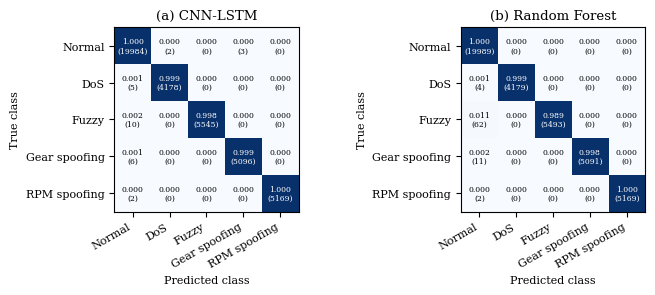

In [ ]:
# ============================================================
# RESUMEN CAR-HACKING: media ± DE por etiqueta y modelo + F1 por clase
# ============================================================
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
res = pd.DataFrame(RESULTS)
ch = res[res["experiment"].str.startswith("CH_")]
summary_ch = (ch.groupby(["experiment", "model"])
              .agg(n_seeds=("seed", "nunique"), macro_f1_mean=("macro_f1", "mean"),
                   macro_f1_sd=("macro_f1", "std"), mcc_mean=("mcc", "mean"),
                   errors_mean=("errors", "mean")).reset_index())
summary_ch[["macro_f1_mean", "macro_f1_sd"]] *= 100
summary_ch.to_csv(os.path.join(OUT_DIR, "CH_summary_mean_sd.csv"), index=False)
print(summary_ch.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

s0 = CH_SEEDS[0]
y = PREDICTIONS[("CH_chronological_y_win", "y_true", 0)]
for mdl in ["CNN-LSTM V3-C", "Random Forest"]:
    print(f"\n===== CH etiqueta por ventana | {mdl} | seed {s0} =====")
    print(classification_report(y, PREDICTIONS[("CH_chronological_y_win", mdl, s0)],
                                labels=range(5), target_names=CH_CLASS_NAMES, digits=4, zero_division=0))

plt.rcParams.update({"font.family": "serif", "font.size": 8, "figure.facecolor": "white", "savefig.dpi": 600})
fig, axes = plt.subplots(1, 2, figsize=(7.16, 3.0))
for ax, mdl, title in zip(axes, ["CNN-LSTM V3-C", "Random Forest"], ["(a) CNN-LSTM", "(b) Random Forest"]):
    cm = confusion_matrix(y, PREDICTIONS[("CH_chronological_y_win", mdl, s0)], labels=range(5))
    cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{cmn[i, j]:.3f}\n({cm[i, j]})", ha="center", va="center", fontsize=5.5,
                    color="white" if cmn[i, j] > 0.5 else "black")
    ax.set_xticks(range(5), CH_CLASS_NAMES, rotation=30, ha="right"); ax.set_yticks(range(5), CH_CLASS_NAMES)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class"); ax.set_title(title)
fig.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "sando_cm_carhacking.pdf")); plt.show()

## Densidad de inyección (Tabla VII del artículo)

In [ ]:
# ============================================================
# DENSIDAD DE INYECCIÓN: recall por nº de tramas inyectadas (media ± DE, 3 semillas)
# ============================================================
w = W_CH["test"]; exp = "CH_chronological_y_win"
y = PREDICTIONS[(exp, "y_true", 0)]
n_inj = np.rint(w["inj_frac"] * 20).astype(int)
rows = []
for lo, hi in [(1, 1), (2, 2), (3, 5), (6, 20)]:
    m = (y > 0) & (n_inj >= lo) & (n_inj <= hi)
    row = {"injected frames": f"{lo}" if lo == hi else f"{lo}-{hi}", "windows": int(m.sum())}
    for mdl in ["CNN-LSTM V3-C", "Random Forest"]:
        r = [float((PREDICTIONS[(exp, mdl, s)][m] == y[m]).mean()) for s in CH_SEEDS]
        row[f"{mdl} mean"] = 100 * np.mean(r)
        row[f"{mdl} sd"] = 100 * np.std(r, ddof=1) if len(r) > 1 else np.nan
    rows.append(row)
dens = pd.DataFrame(rows)
dens.to_csv(os.path.join(OUT_DIR, "CH_density_recall.csv"), index=False)
print(dens.to_string(index=False, float_format=lambda x: f"{x:.2f}"))


injected frames  windows  CNN-LSTM V3-C mean  CNN-LSTM V3-C sd  Random Forest mean  Random Forest sd
              1       32               45.83              7.22                9.38              3.12
              2       89               94.01              1.72               76.78              4.54
            3-5     3622               99.91              0.03               99.28              0.03
           6-20    16268              100.00              0.00              100.00              0.00
